Name: Praveen Kumar Sarkar        Reg No. GF202455013

# California Housing Dataset: Correlation Matrix & Heatmap
This notebook computes and visualizes the correlation matrix for the California Housing dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

## 1. Load the Dataset

In [2]:
california = fetch_california_housing()

df = pd.DataFrame(
    california.data,
    columns=california.feature_names
)
df["MedHouseVal"] = california.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Compute the Correlation Matrix

In [3]:
correlation_matrix = df.corr()
correlation_matrix

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


## 3. Visualize the Correlation Matrix

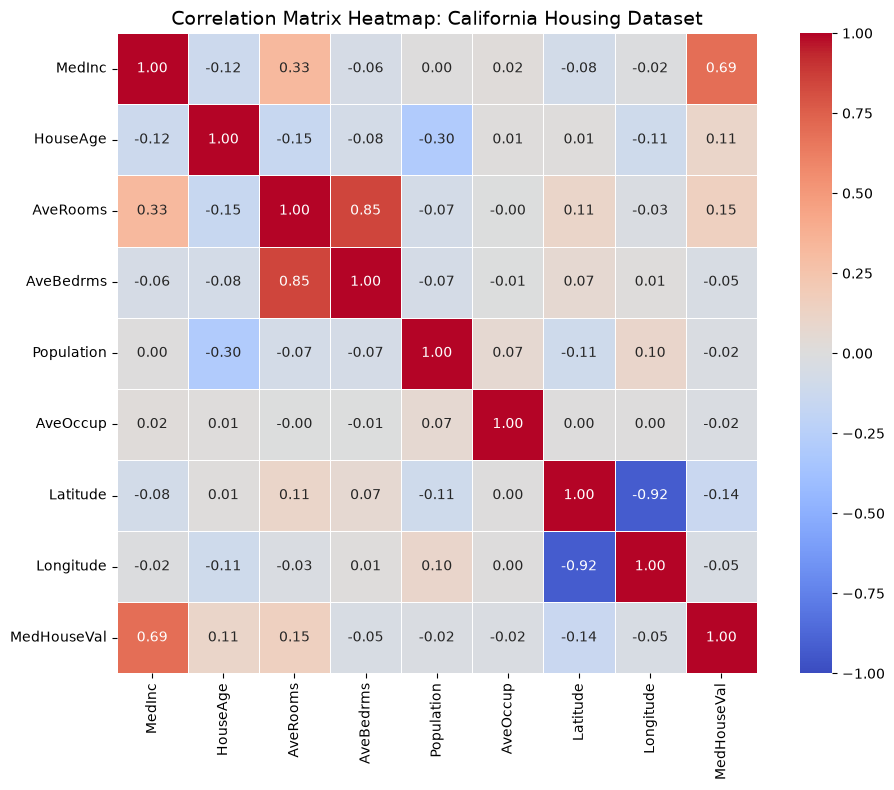

In [4]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix Heatmap: California Housing Dataset", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Interpretation

- **Strong positive correlation:** Variables increase together, such as `MedInc` and `MedHouseVal`.
- **Strong negative correlation:** One variable tends to decrease as the other increases.
- **Multicollinearity warning:** Highly correlated features, such as `AveRooms` and `AveBedrms`, may cause instability in linear models.

Top features correlated with MedHouseVal:
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Name: MedHouseVal, dtype: float64


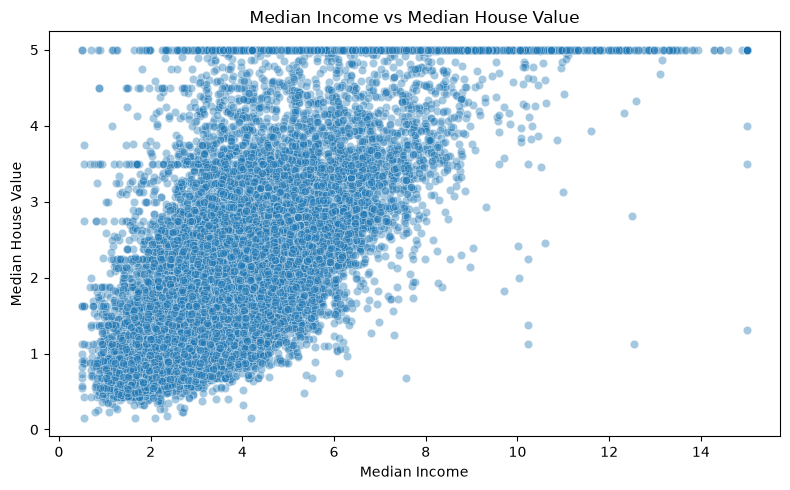

In [5]:
# Strongest correlations with the target variable
strongest_corr = correlation_matrix["MedHouseVal"].drop("MedHouseVal").sort_values(ascending=False)
print("Top features correlated with MedHouseVal:")
print(strongest_corr.head(5))

# Scatter plot to visualize the relationship between median income and house value
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MedInc", y="MedHouseVal", alpha=0.4)
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.tight_layout()
plt.show()

In [6]:
# Highest positive and negative correlations based on analysis
corr_with_target = correlation_matrix["MedHouseVal"].drop("MedHouseVal")

highest_positive = corr_with_target.sort_values(ascending=False).head(3)
highest_negative = corr_with_target.sort_values(ascending=True).head(3)

print("Highest positive correlations with MedHouseVal:")
print(highest_positive)
print("\nHighest negative correlations with MedHouseVal:")
print(highest_negative)


Highest positive correlations with MedHouseVal:
MedInc      0.688075
AveRooms    0.151948
HouseAge    0.105623
Name: MedHouseVal, dtype: float64

Highest negative correlations with MedHouseVal:
Latitude    -0.144160
AveBedrms   -0.046701
Longitude   -0.045967
Name: MedHouseVal, dtype: float64
